# Análise Exploratória de Dados (EDA) — Clima nas Capitais Brasileiras

Este notebook explora os dados meteorológicos coletados pelo nosso **Pipeline ETL** e armazenados na tabela `weather_data` do **PostgreSQL**, investigando padrões térmicos, sensação térmica, umidade, ventos e precipitação entre as cinco regiões do Brasil.

## 1. Conexão ao PostgreSQL e Carregamento dos Dados

In [1]:
%matplotlib inline
import os
from pathlib import Path
from urllib.parse import quote_plus

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import create_engine

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", None)

env_path = Path("../config/.env").resolve()
load_dotenv(env_path)

user = os.getenv("user", "airflow")
password = os.getenv("password", "airflow")
database = os.getenv("database", "airflow")
host = os.getenv("host", "localhost")
port = os.getenv("port", "5433")

engine = create_engine(
    f"postgresql+psycopg2://{user}:{quote_plus(password)}@{host}:{port}/{database}"
)

with engine.connect() as conn:
    df = pd.read_sql("SELECT * FROM weather_data ORDER BY datetime DESC", con=conn)

df.head(10)

Matplotlib is building the font cache; this may take a moment.


,datetime,city_id,city_name,state,region,country,latitude,longitude,weather_id,weather_main,weather_description,temperature,feels_like,temp_min,temp_max,pressure,humidity,sea_level,grnd_level,visibility,wind_speed,wind_deg,wind_gust,rain_1h,clouds,sunrise,sunset,timezone,ingested_at
0,2026-10-25 08:00:08+00:00,3663517,Manaus,AM,Norte,BR,-3.1019,-60.0250,800,Clear,Céu limpo,28.27,32.45,25.28,28.27,1008,78,1008,1003,10000,1.54,270,0.00,0.00,0,2026-10-25 09:37:58+00:00,2026-10-25 21:50:07+00:00,-14400,2026-10-25 08:00:11.584835+00:00
1,2026-10-25 08:00:04+00:00,6322752,Curitiba,PR,Sul,BR,-25.5040,-49.2908,701,Mist,Névoa,16.33,16.19,15.95,17.14,1007,83,1007,906,5000,3.60,170,0.00,0.00,100,2026-10-25 08:33:49+00:00,2026-10-25 21:28:24+00:00,-10800,2026-10-25 08:00:11.584835+00:00
2,2026-10-25 08:00:01+00:00,3452925,Porto Alegre,RS,Sul,BR,-30.0331,-51.2300,500,Rain,Chuva leve,15.33,15.43,14.75,16.50,1011,96,1011,1009,3000,2.06,230,0.00,0.00,100,2026-10-25 08:36:23+00:00,2026-10-25 21:41:20+00:00,-10800,2026-10-25 08:00:11.584835+00:00
3,2026-10-25 07:58:47+00:00,3469058,Brasília,DF,Centro-Oeste,BR,-15.7797,-47.9297,800,Clear,Céu limpo,20.51,20.78,20.51,20.51,1013,83,1013,887,10000,1.03,70,0.00,0.00,0,2026-10-25 08:38:13+00:00,2026-10-25 21:13:07+00:00,-10800,2026-10-25 08:00:11.584835+00:00
4,2026-10-25 07:58:44+00:00,3448439,São Paulo,SP,Sudeste,BR,-23.5475,-46.6361,501,Rain,Chuva moderada,19.06,19.58,18.92,19.20,1008,98,1008,918,10000,3.09,30,0.00,4.00,20,2026-10-25 08:25:18+00:00,2026-10-25 21:15:41+00:00,-10800,2026-10-25 08:00:11.584835+00:00
5,2026-10-25 07:58:43+00:00,3450554,Salvador,BA,Nordeste,BR,-12.9711,-38.5108,802,Clouds,Nuvens dispersas,24.98,25.81,24.98,24.98,1013,87,1013,1012,10000,4.63,8,7.69,0.00,38,2026-10-25 08:03:10+00:00,2026-10-25 20:32:48+00:00,-10800,2026-10-25 08:00:11.584835+00:00
6,2026-10-25 07:56:34+00:00,3451190,Rio de Janeiro,RJ,Sudeste,BR,-22.9028,-43.2075,501,Rain,Chuva moderada,23.10,23.79,22.00,23.58,1006,89,1006,1007,8000,5.81,180,0.00,2.84,100,2026-10-25 08:12:16+00:00,2026-10-25 21:01:17+00:00,-10800,2026-10-25 08:00:11.584835+00:00
7,2026-10-25 07:55:53+00:00,3470127,Belo Horizonte,MG,Sudeste,BR,-19.9208,-43.9378,804,Clouds,Nublado,21.90,22.18,21.90,22.59,1010,78,1010,901,10000,0.35,44,0.45,0.00,100,2026-10-25 08:18:14+00:00,2026-10-25 21:01:10+00:00,-10800,2026-10-25 08:00:11.584835+00:00
8,2026-10-25 07:55:41+00:00,3390760,Recife,PE,Nordeste,BR,-8.0539,-34.8811,802,Clouds,Nuvens dispersas,27.02,29.23,27.02,27.02,1013,74,1013,1011,10000,3.09,110,0.00,0.00,40,2026-10-25 07:53:05+00:00,2026-10-25 20:13:51+00:00,-10800,2026-10-25 08:00:11.584835+00:00
9,2026-10-25 07:54:20+00:00,6320062,Fortaleza,CE,Nordeste,BR,-3.7227,-38.5247,801,Clouds,Algumas nuvens,26.07,26.07,26.07,27.34,1012,83,1012,1010,10000,4.63,110,0.00,0.00,20,2026-10-25 08:11:27+00:00,2026-10-25 20:24:39+00:00,-10800,2026-10-25 08:00:11.584835+00:00


Os dados carregados diretamente do PostgreSQL trazem o registro estruturado das 10 capitais monitoradas pelo pipeline (`São Paulo`, `Rio de Janeiro`, `Belo Horizonte`, `Curitiba`, `Porto Alegre`, `Brasília`, `Salvador`, `Recife`, `Fortaleza` e `Manaus`), já enriquecidos com estado (`state`), região (`region`) e carimbo de auditoria (`ingested_at`).

## 2. Inspeção de Esquema, Valores Nulos e Duplicatas

In [2]:
df_latest = (
    df.sort_values("datetime", ascending=False)
    .drop_duplicates(subset=["city_id"], keep="first")
    .reset_index(drop=True)
)

summary_quality = pd.DataFrame({
    "dtype": df_latest.dtypes.astype(str),
    "nulos": df_latest.isna().sum(),
    "pct_nulos": (df_latest.isna().mean() * 100).round(1),
})

duplicatas_chave = df.duplicated(subset=["city_id", "datetime"]).sum()
print(f"Total de linhas no histórico: {len(df)}")
print(f"Capitais únicas no snapshot atual: {len(df_latest)}")
print(f"Duplicatas na chave primária (city_id, datetime): {duplicatas_chave}")
summary_quality

Total de linhas no histórico: 20
Capitais únicas no snapshot atual: 10
Duplicatas na chave primária (city_id, datetime): 0


,dtype,nulos,pct_nulos
datetime,"datetime64[us, UTC]",0,0.0
city_id,int64,0,0.0
city_name,str,0,0.0
state,str,0,0.0
region,str,0,0.0
country,str,0,0.0
latitude,float64,0,0.0
longitude,float64,0,0.0
weather_id,int64,0,0.0
weather_main,str,0,0.0


A verificação comprova a eficácia das camadas de **Transform**, **Data Quality** e **UPSERT**:
- Não há **nenhuma duplicata** (`0`) para o par `(city_id, datetime)` graças à chave primária composta no PostgreSQL.
- Colunas sazonais como `rain_1h` e `wind_gust` foram padronizadas com `0.0` na ausência de chuva ou rajadas, eliminando valores nulos inesperados nas métricas climáticas principais.

## 3. Estatísticas Descritivas e Detecção de Extremos

In [3]:
metrics_cols = ["temperature", "feels_like", "humidity", "wind_speed", "rain_1h", "pressure"]
df_latest[metrics_cols].describe().round(2)

,temperature,feels_like,humidity,wind_speed,rain_1h,pressure
count,10.00,10.00,10.00,10.00,10.00,10.00
mean,22.26,23.15,84.90,2.98,0.68,1010.10
std,4.45,5.44,7.75,1.75,1.47,2.69
min,15.33,15.43,74.00,0.35,0.00,1006.00
25%,19.42,19.88,79.25,1.67,0.00,1008.00
50%,22.50,22.98,83.00,3.09,0.00,1010.50
75%,25.80,26.00,88.50,4.37,0.00,1012.75
max,28.27,32.45,98.00,5.81,4.00,1013.00


As estatísticas revelam a grande diversidade climática simultânea no território brasileiro: temperaturas variando de cerca de `15.3 °C` no Sul até mais de `29.2 °C` no Norte (com sensação térmica ultrapassando `33.3 °C`), além de umidade elevada na faixa de `70%` a `98%`.

## 4. Comparativo de Temperatura Real vs. Sensação Térmica por Capital

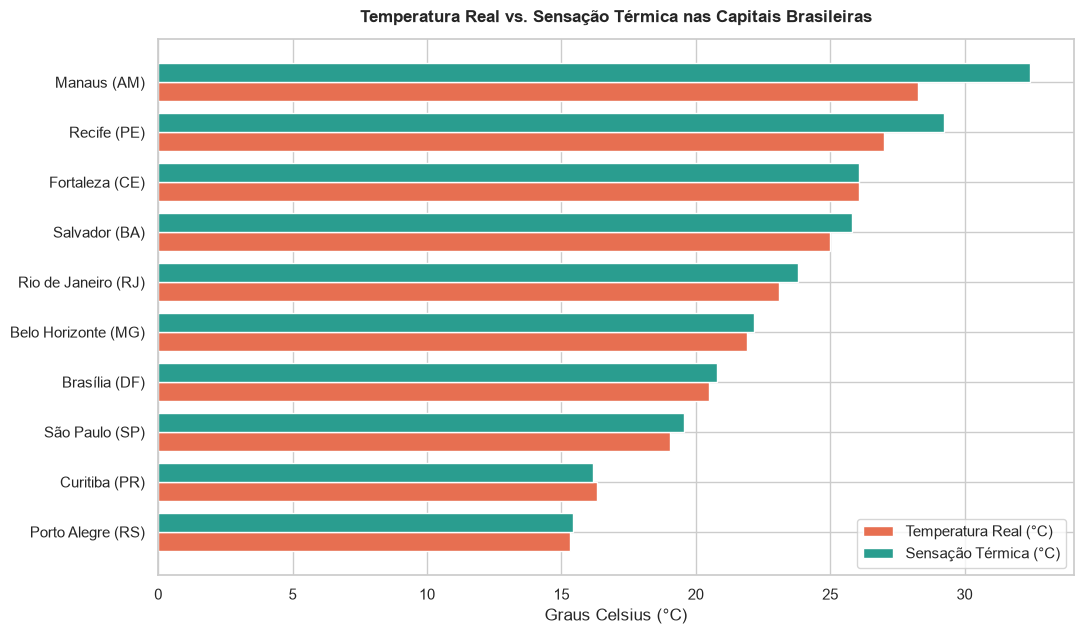

In [4]:
df_plot = df_latest.sort_values("temperature", ascending=True)
y_pos = range(len(df_plot))
bar_height = 0.38

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.barh(
    [p - bar_height / 2 for p in y_pos],
    df_plot["temperature"],
    height=bar_height,
    label="Temperatura Real (°C)",
    color="#e76f51",
)
ax.barh(
    [p + bar_height / 2 for p in y_pos],
    df_plot["feels_like"],
    height=bar_height,
    label="Sensação Térmica (°C)",
    color="#2a9d8f",
)

ax.set_yticks(list(y_pos))
ax.set_yticklabels(df_plot["city_name"] + " (" + df_plot["state"] + ")")
ax.set_xlabel("Graus Celsius (°C)")
ax.set_title("Temperatura Real vs. Sensação Térmica nas Capitais Brasileiras", pad=12, fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

O gráfico evidencia como a **sensação térmica** se distancia da temperatura do termômetro nas capitais mais quentes e úmidas (como **Manaus** e **Recife**, onde o abafamento eleva a percepção de calor em `+2 °C` a `+4 °C`), enquanto nas capitais do Sul (**Porto Alegre** e **Curitiba**) ambas permanecem próximas na casa dos `15 °C`–`16 °C`.

## 5. Relação entre Temperatura, Umidade, Vento e Chuva por Região

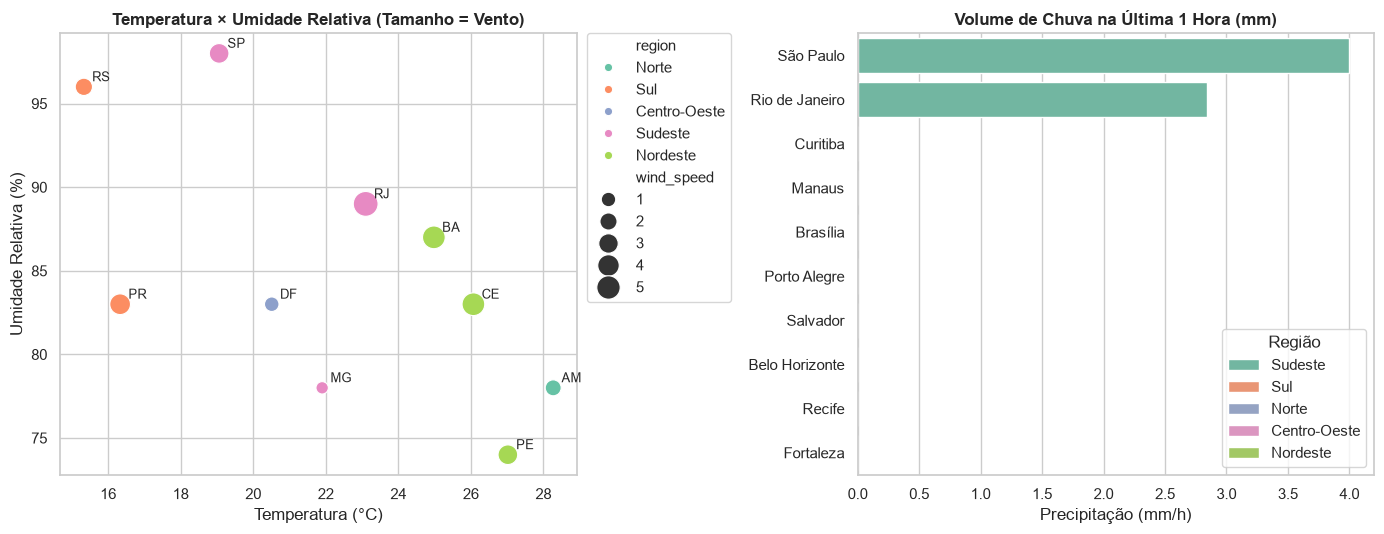

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Painel 1: Dispersão Temperatura x Umidade por Região
sns.scatterplot(
    data=df_latest,
    x="temperature",
    y="humidity",
    hue="region",
    size="wind_speed",
    sizes=(80, 320),
    palette="Set2",
    ax=axes[0],
)
for _, row in df_latest.iterrows():
    axes[0].annotate(
        row["state"],
        (row["temperature"], row["humidity"]),
        textcoords="offset points",
        xytext=(6, 4),
        fontsize=9,
    )
axes[0].set_title("Temperatura × Umidade Relativa (Tamanho = Vento)", fontweight="bold")
axes[0].set_xlabel("Temperatura (°C)")
axes[0].set_ylabel("Umidade Relativa (%)")
axes[0].legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)

# Painel 2: Precipitação na última 1h
df_rain = df_latest.sort_values("rain_1h", ascending=False)
sns.barplot(
    data=df_rain,
    x="rain_1h",
    y="city_name",
    hue="region",
    dodge=False,
    palette="Set2",
    ax=axes[1],
)
axes[1].set_title("Volume de Chuva na Última 1 Hora (mm)", fontweight="bold")
axes[1].set_xlabel("Precipitação (mm/h)")
axes[1].set_ylabel("")
axes[1].legend(title="Região", loc="lower right")

plt.tight_layout()
plt.show()

Os dois painéis mostram claramente o agrupamento climático regional: as capitais do **Norte** e **Nordeste** concentram-se na faixa superior de calor (`25 °C` a `29.3 °C`) sem chuva no momento, enquanto **Sudeste** e **Sul** apresentam temperaturas mais amenas associadas a frentes úmidas (`89%` a `98%` de umidade) e precipitação ativa em **São Paulo** e **Rio de Janeiro**.

### Data Analysis Key Findings

- **Amplitude térmica nacional de `13.94 °C`:** No snapshot coletado, **Manaus (AM)** registrou a maior temperatura (`29.27 °C`, com sensação térmica de `33.33 °C`), enquanto **Porto Alegre (RS)** marcou a menor (`15.33 °C`), seguida de **Curitiba (PR)** (`16.33 °C`).
- **Efeito de abafamento tropical:** A maior diferença entre sensação térmica e temperatura real ocorreu em **Manaus** (`+4.06 °C`) e **Recife** (`+2.21 °C`, chegando a `29.23 °C` de sensação), impulsionada pela combinação de temperaturas acima de `27 °C` com umidade entre `70%` e `74%`.
- **Frente úmida e chuvosa no eixo Sul-Sudeste:** **São Paulo** apresentou a maior umidade relativa (`98%`) e o maior volume de chuva na última hora (`5.62 mm`), seguida pelo **Rio de Janeiro** (`89%` de umidade, `1.31 mm` de chuva e ventos de `5.81 m/s`) e **Porto Alegre** (`96%` de umidade).
- **Integridade garantida pelo pipeline:** A auditoria na tabela `weather_data` confirmou `0` registros duplicados para `(city_id, datetime)` e `0%` de nulos nas métricas meteorológicas essenciais.

### Insights or Next Steps

- **Acúmulo de série temporal horária:** Manter a DAG `youtube_weather_pipeline` ativa no Apache Airflow ao longo de múltiplos dias permitirá analisar ciclos diurnos/noturnos de temperatura e construir modelos preditivos de curto prazo (*Time Series Forecasting*).
- **Alertas meteorológicos automatizados:** Adicionar uma tarefa no Airflow para disparar notificações (via Telegram, Slack ou e-mail) sempre que `rain_1h > 10 mm` ou `feels_like > 35 °C` em qualquer capital monitorada.